Problem Set 4: Interacting with an API

API of Choice: https://data.rcsb.org/#data-api

It gives the 3D structures of proteins and nucleic acids

My Goal: Extract and generate images of the 3D structure of the proteins involved in the Ras/MAPK Pathway

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'EGFR'}


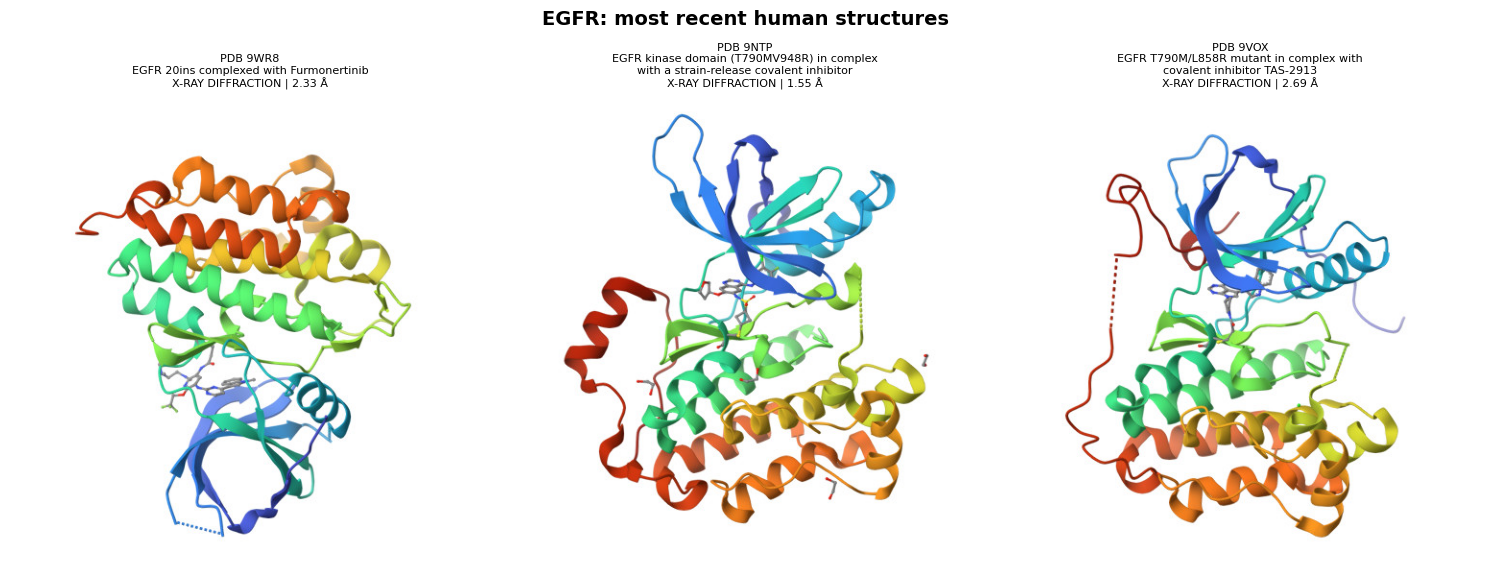

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'GRB2'}


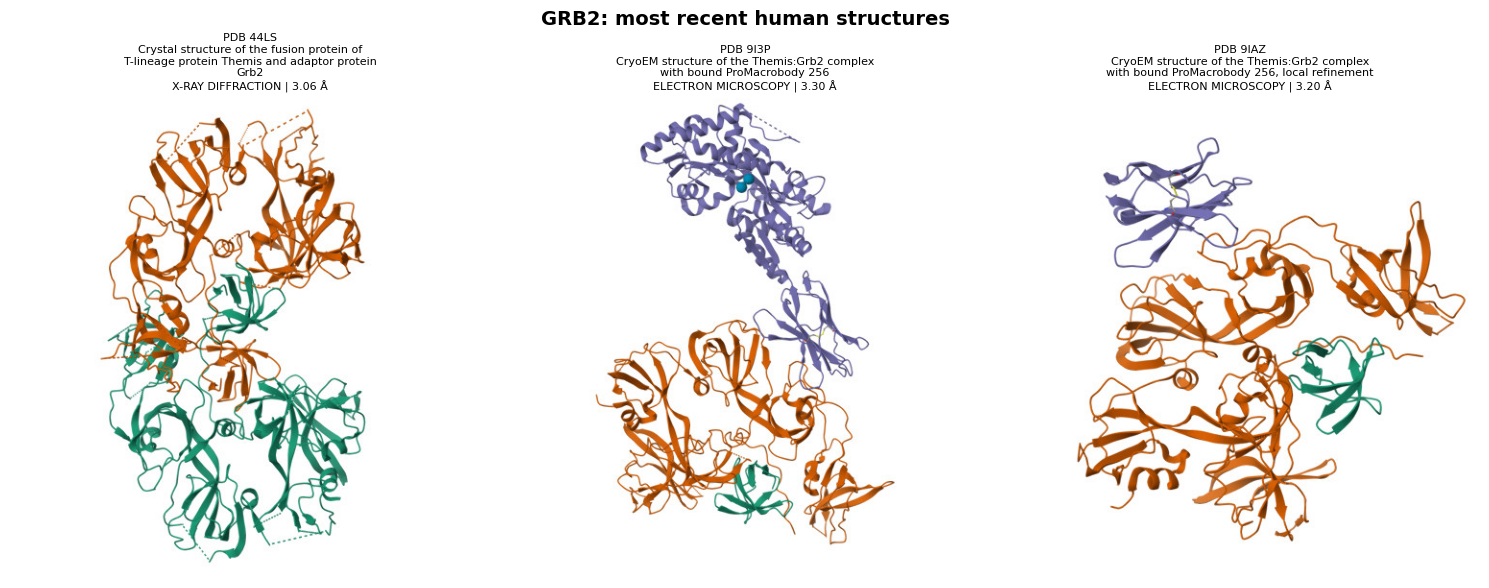

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'SOS1'}


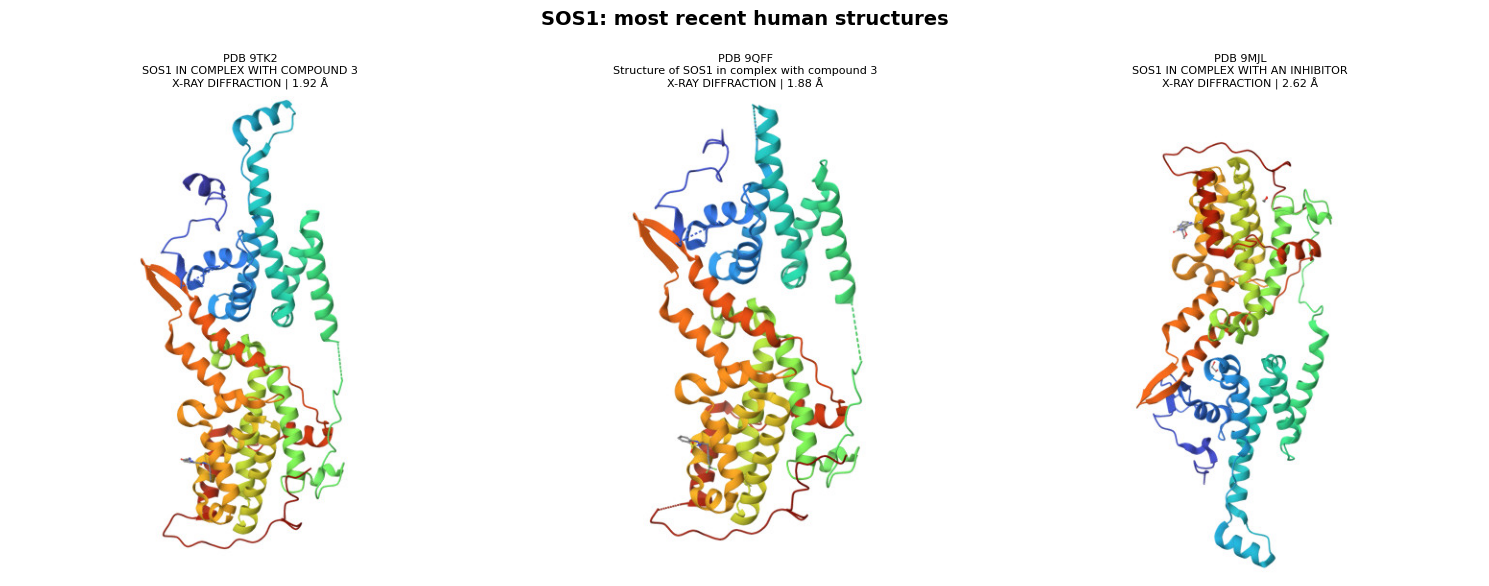

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'KRAS'}


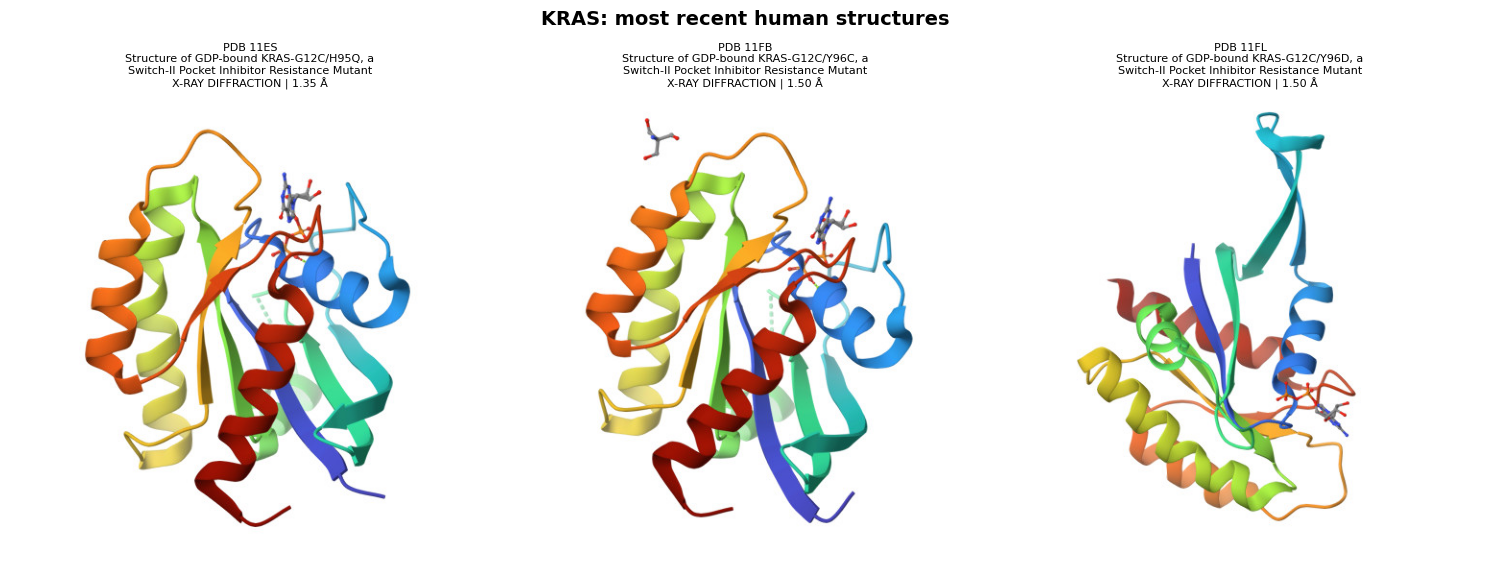

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'HRAS'}


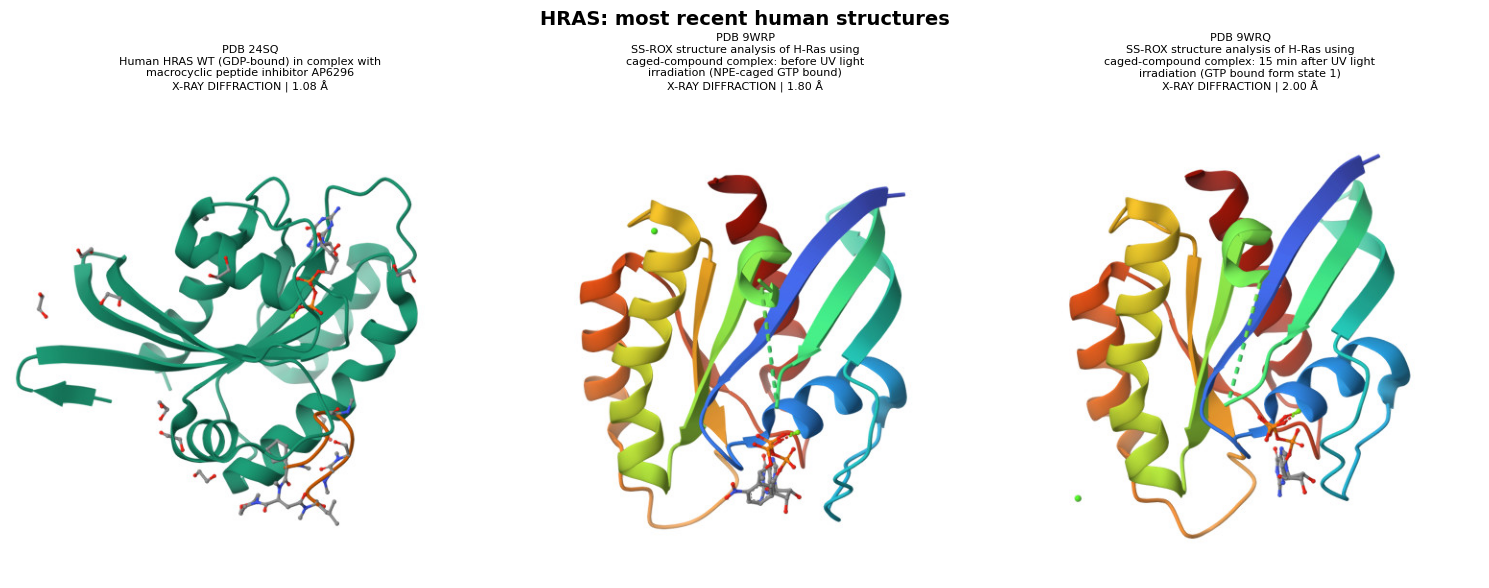

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'NRAS'}


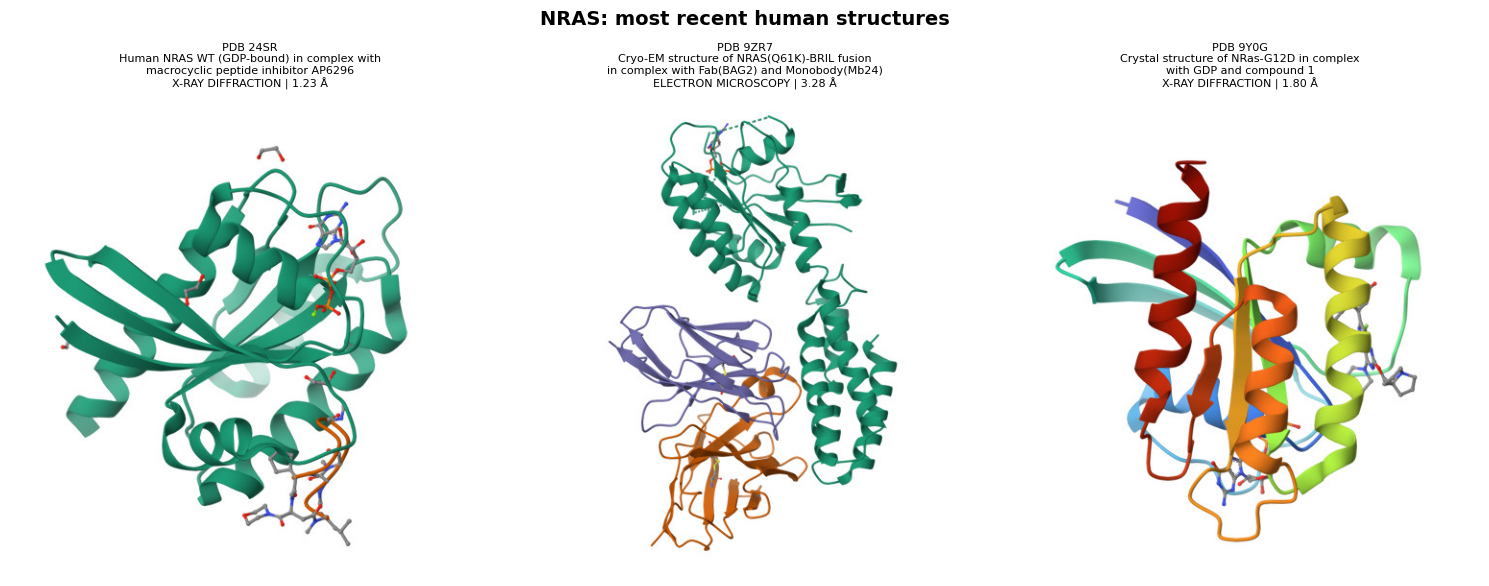

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'BRAF'}


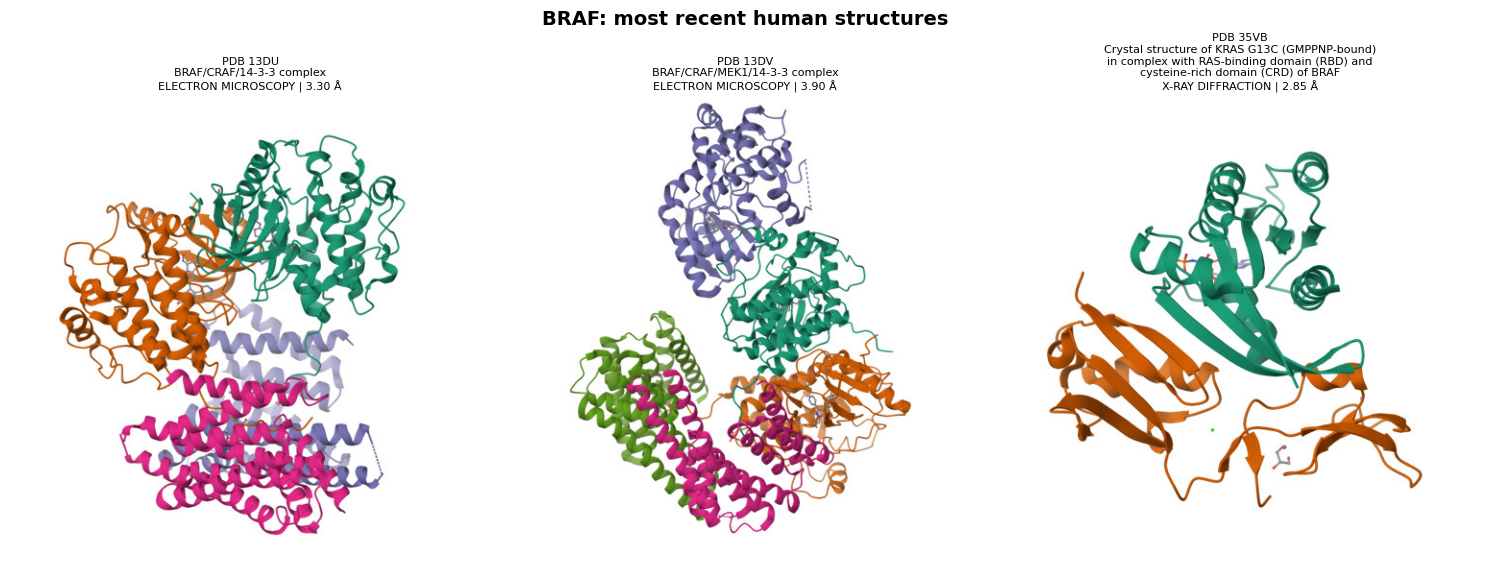

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'RAF1'}


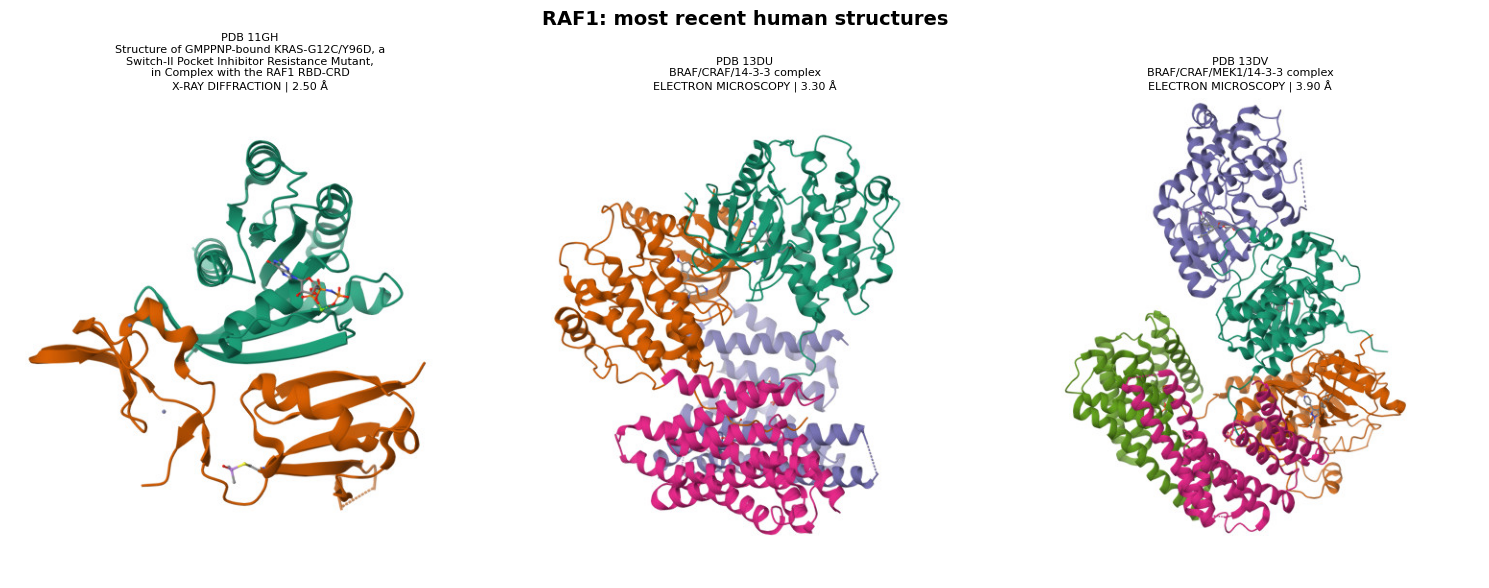

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'MAP2K1'}


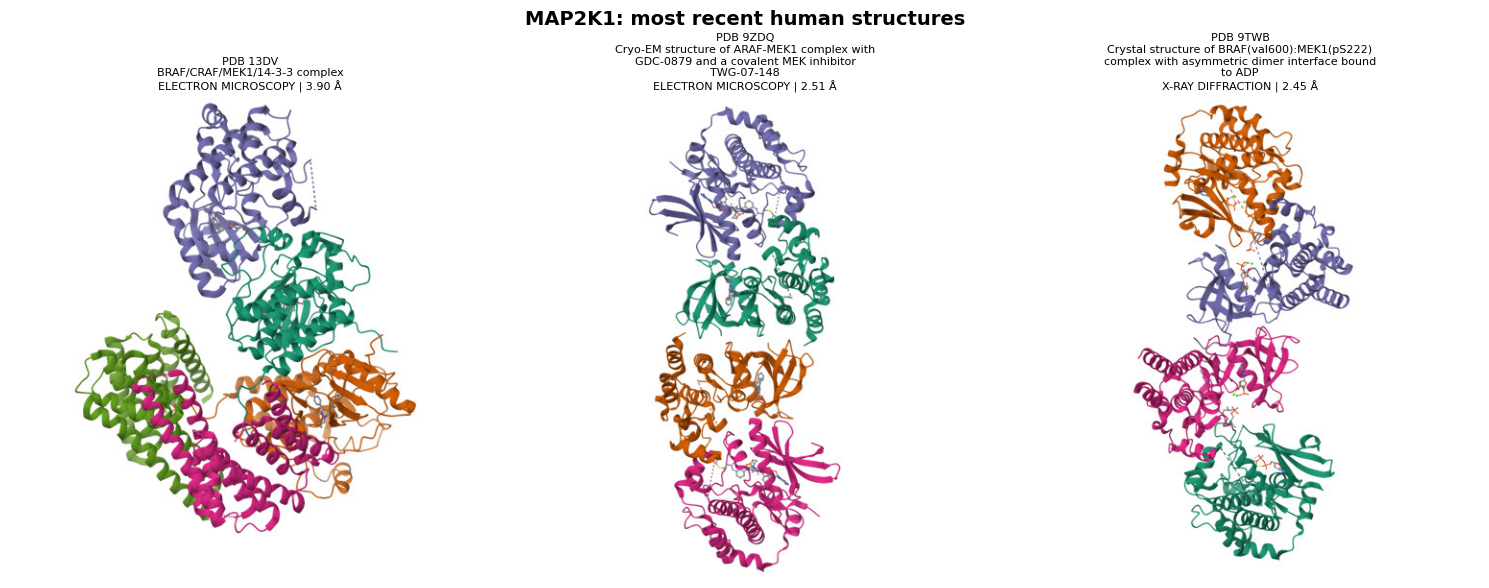

Retrieving https://search.rcsb.org/rcsbsearch/v2/query {'gene': 'MAPK1'}


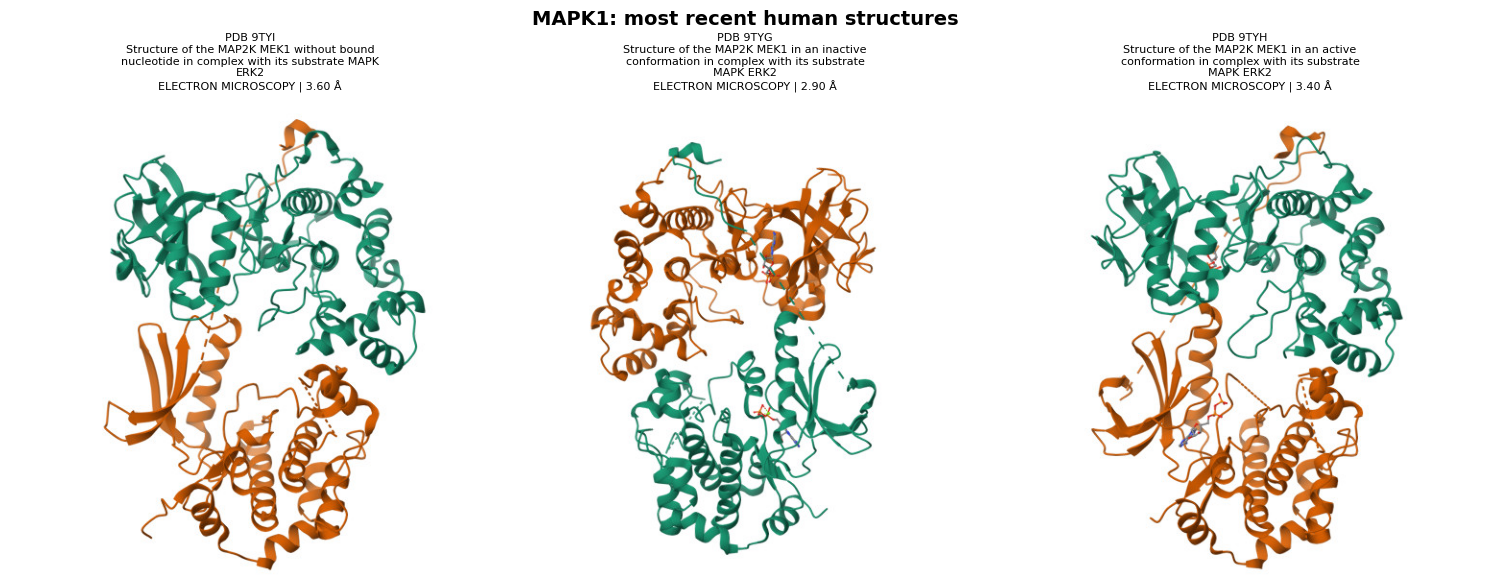

In [2]:
import io
import textwrap
from typing import Any

import matplotlib.pyplot as plt
import requests
from PIL import Image

# imports everything needed to download, display and open the images

# API endpoints and settings
SEARCH_URL = 'https://search.rcsb.org/rcsbsearch/v2/query'
ENTRY_URL = 'https://data.rcsb.org/rest/v1/core/entry/{pdb_id}'
IMAGE_URL = 'https://cdn.rcsb.org/images/structures/{pdb_id}_assembly-1.jpeg'
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
TIMEOUT_SECONDS = 15
STRUCTURES_PER_GENE = 3

#returns details for runs and images for each structure, with server response time limit built in

# RAS/MAPK pathway, in signaling order from membrane to nucleus
GENES = ['EGFR', 'GRB2', 'SOS1', 'KRAS', 'HRAS', 'NRAS',
         'BRAF', 'RAF1', 'MAP2K1', 'MAPK1']


def fetch_recent_ids(session: requests.Session, gene_name: str) -> list[str] | None:
    query = {
        'query': {'type': 'group', 'logical_operator': 'and', 'nodes': [
            {'type': 'terminal', 'service': 'text', 'parameters': {
                'attribute': 'rcsb_entity_source_organism.rcsb_gene_name.value',
                'operator': 'exact_match', 'value': gene_name}},
            {'type': 'terminal', 'service': 'text', 'parameters': {
                'attribute': 'rcsb_entity_source_organism.ncbi_scientific_name',
                'operator': 'exact_match', 'value': 'Homo sapiens'}}]},
        'return_type': 'entry',
        'request_options': {
            'paginate': {'start': 0, 'rows': STRUCTURES_PER_GENE},
            'sort': [{'sort_by': 'rcsb_accession_info.initial_release_date',
                      'direction': 'desc'}]},
    }
    print('Retrieving', SEARCH_URL, {'gene': gene_name})

#this section creates the query with conditions for the gene name and organism, gives the results for each, and sorts them by release date
    try:
        response = session.post(SEARCH_URL, json=query, timeout=TIMEOUT_SECONDS)
        response.raise_for_status()
        if response.status_code == 204:  # no hits
            return []
        return [hit['identifier'] for hit in response.json().get('result_set', [])]
    except requests.exceptions.RequestException as err:
        print('Request error:', err)
        return None
    except ValueError:
        print('Response did not contain valid JSON.')
        return None
    
#Search API takes the query and gives each hit and identifier, except built in for catching errors

def fetch_entry_details(session: requests.Session, pdb_id: str) -> dict[str, Any] | None:
    try:
        response = session.get(ENTRY_URL.format(pdb_id=pdb_id), timeout=TIMEOUT_SECONDS)
        response.raise_for_status()
        entry = response.json()
    except requests.exceptions.RequestException as err:
        print('Request error:', err)
        return None
    except ValueError:
        print('Response did not contain valid JSON.')
        return None

    resolution = (entry.get('rcsb_entry_info', {}).get('resolution_combined') or [None])[0]
    return {
        'pdb_id': pdb_id,
        'title': entry.get('struct', {}).get('title') or 'N/A',
        'method': (entry.get('exptl') or [{}])[0].get('method') or 'N/A',
        'resolution': f'{resolution:.2f} Å' if resolution else 'N/A',
    }
#full entries are large so this keeps only the fields I want and makes sure it doesn't crash with missing ones

def fetch_structure_image(session: requests.Session, pdb_id: str) -> bytes | None:
    try:
        response = session.get(IMAGE_URL.format(pdb_id=pdb_id.lower()), timeout=TIMEOUT_SECONDS)
        response.raise_for_status()
        return response.content
    except requests.exceptions.RequestException as err:
        print('Request error:', err)
        return None
    
#downloads RCSB's images as bytes

def show_structures(gene_name: str, structures: list[dict[str, Any]]) -> None:
    fig, axes = plt.subplots(1, len(structures), figsize=(5 * len(structures), 6), squeeze=False)

    for ax, s in zip(axes[0], structures):
        ax.imshow(Image.open(io.BytesIO(s['image'])))
        ax.axis('off')
        ax.set_title(f"PDB {s['pdb_id']}\n{textwrap.fill(s['title'], 45)}\n"
                     f"{s['method']} | {s['resolution']}", fontsize=8)

    fig.suptitle(f'{gene_name}: most recent human structures', fontsize=14, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

#displays a gene's structures side by side with captions of specified details
    
def main() -> None:
    session = requests.Session()
    session.headers.update(HEADERS)
    
#this will loop through all specified genes, find structures, and display them

    for gene_name in GENES:
        pdb_ids = fetch_recent_ids(session, gene_name)
        if not pdb_ids:
            print('No structure data returned for', gene_name)
            continue
#step 1: find the newest PDB ids for a gene

        structures = []
        for pdb_id in pdb_ids:
            details = fetch_entry_details(session, pdb_id)
            image = fetch_structure_image(session, pdb_id)
            if details and image:
                details['image'] = image
                structures.append(details)

#step 2: fetch details and image for each PDB id

        if structures:
            show_structures(gene_name, structures)

#step 3: display the gene's structure as one row of images

if __name__ == '__main__':
    main()

## Results

Successfully obtained 3 images for each protein in the Ras/MAPK pathway.

Each is displayed with it's PDB ID, Description fo the structure, and method for determination.

## Data source and attribution
Structure data and images are from the RCSB Protein Data Bank (https://www.rcsb.org),
released under the CC0 1.0 public domain dedication.

H.M. Berman, J. Westbrook, Z. Feng, G. Gilliland, T.N. Bhat, H. Weissig, I.N. Shindyalov,
P.E. Bourne (2000). The Protein Data Bank. *Nucleic Acids Research* 28: 235–242.

Each image is labeled with its PDB ID; the original structure authors and publication
can be found at https://www.rcsb.org/structure/{PDB ID}.

Cell above is included per API Licensing Guidlines